# Lid-driven cavity on this repository's optimiser stack

Steady incompressible Navier-Stokes at $\mathrm{Re}=100$ on $[0,1]^2$:

$$\mathbf{u}\!\cdot\!\nabla\mathbf{u} + \nabla p - \tfrac{1}{\mathrm{Re}}\nabla^2\mathbf{u}=0,\qquad \nabla\!\cdot\!\mathbf{u}=0.$$

The lid ($y=1$) moves with $u=4x(1-x)$; the other walls are no-slip.

No `pinn` import: the notebook drives the optimisers that live in this repository.

* `stationary.dsgnar.dsgnar_phase` — the doubly-sketched Gauss-Newton used for the stationary runs (see `Stationary/DSGNAR.md`), configured through `stationary.problem.Config`.
* `Crunch.Optimizers.minimize(..., options={"update_method": "ssbroyden2"})` — the JAX Crunch fork of `jax.scipy.optimize` with the self-scaling Broyden (`Jax/Crunch`).

The residual/loss adapter (`FlatObjective` below) mirrors `Stationary/stationary/flat_objective.py`,
so the loss handed to either optimiser is the same plain mean-square residual.

Reference field: `ldc/reference_gen/ldc_reference.npz` (Re = 100, same lid profile), written by
`ldc/reference_gen/make_ldc_reference.py`.
`SMOKE = True` (the default) is a **plumbing check**: it runs in about five minutes on a CPU and
drives the loss down ~170x, but it will *not* reproduce the reference field.  Set `SMOKE = False`
and raise `DSGNAR_STEPS` for a real solve -- at these sizes the cost is roughly linear in the step
count, so a few thousand DSGNAR iterations means hours on CPU.

### Running this on the hub (JupyterHub, GPU node)

It must run on a kernel registered from the **CUDA** environment, `Stationary/.venv` -- a kernel
from `~/venvs/pinn` has no CUDA jax and silently runs on the CPU (that is what the 2026-10-19 run
did: 200 DSGNAR iterations in 2436 s).  One-time setup, in the JupyterLab terminal:

```bash
bash ~/serafin/Julia/PINN/ldc/setup_gpu_kernel.sh
```

then pick **PINN (jax, CUDA)** as the kernel.  Cell 1 refuses to run on the hub if jax falls back
to the CPU.  A notebook kernel dies with the Jupyter server, so for a long solve prefer `nohup`
from the JupyterLab terminal.


In [1]:
import os, sys, time, pathlib


def _repo_root(start=None):
    """Walk up from the kernel's cwd (and from the hub layouts) to the checkout root."""
    starts = [pathlib.Path(start or pathlib.Path.cwd()).resolve(),
              pathlib.Path.home() / "serafin" / "Julia" / "PINN",   # hub node (JupyterLab)
              pathlib.Path.home() / "Julia" / "PINN"]               # login node
    for base in starts:
        for p in (base, *base.parents):
            if (p / "Stationary" / "stationary" / "dsgnar.py").exists():
                return p
    raise RuntimeError("repo root not found (no Stationary/stationary/dsgnar.py above cwd or $HOME)")


REPO = _repo_root()
FIGDIR = REPO / "ldc" / "figures"   # saved figures land here (visible in JupyterLab's file browser)
FIGDIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl")   # ~/.matplotlib is not writable here
# Must be set BEFORE the first `import jax` in this kernel (HUB.md 8.2), or the kernel grabs
# 75% of the hub GPU.  If jax is already imported, restart the kernel.
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
sys.path.insert(0, str(REPO / "Stationary"))        # stationary.dsgnar, stationary.problem.Config
sys.path.insert(0, str(REPO / "Jax"))               # Crunch: SSBroyden

import numpy as np
import jax
import jax.numpy as jnp
from jax.flatten_util import ravel_pytree
import matplotlib.pyplot as plt

from stationary.problem import Config            # dsgnar_phase reads its dsgnar_* fields
from stationary.dsgnar import dsgnar_phase       # doubly-sketched Gauss-Newton
from Crunch.Optimizers.minimize import minimize  # SSBroyden

jax.config.update("jax_enable_x64", True)

# The hub gets these notebooks from the CUDA environment (Stationary/.venv).  If the kernel
# was registered from ~/venvs/pinn instead, jax silently falls back to the CPU -- that is what
# the 2026-10-19 run did (200 DSGNAR iterations in 2436 s on ['cpu:0']).  Fail loudly there.
REQUIRE_GPU = pathlib.Path.home().joinpath("serafin").is_dir()      # true on the hub GPU node
backend, devices = jax.default_backend(), jax.devices()
print(f"repo {REPO}")
print(f"jax {jax.__version__} | backend {backend} | {[str(d) for d in devices]} | "
      f"x64={jax.config.jax_enable_x64}")
if backend == "gpu":
    print(f"GPU: {devices[0].device_kind}")
    try:
        mem = devices[0].memory_stats()
        print(f"memory: {mem['bytes_in_use'] / 2**30:.1f} GiB in use of "
              f"{mem['bytes_limit'] / 2**30:.1f} GiB")
    except Exception:
        pass
elif REQUIRE_GPU:
    raise RuntimeError(
        "CPU kernel on the hub: jax reports backend='cpu', so this notebook would run on the "
        "CPU.\nSwitch to a kernel registered from the CUDA environment:\n"
        "   bash ~/serafin/Julia/PINN/ldc/setup_gpu_kernel.sh      # once, in the JupyterLab terminal\n"
        "then Kernel -> Change Kernel -> 'PINN (jax, CUDA)' (restart the kernel if it was already up).")
else:
    print("note: no GPU here (fine for a Mac/CPU sanity run); the hub must use the CUDA kernel.")

repo /serafin/reula/Julia/PINN
jax 0.11.1 | backend gpu | ['cuda:0'] | x64=True
GPU: NVIDIA A30
memory: 0.0 GiB in use of 13.5 GiB


In [2]:
def init_siren(key, in_dim=2, hidden=(48, 48, 48), out_dim=3, omega0=3.0, omega_h=1.0):
    """SIREN (Sitzmann et al.): sin(Wx+b) layers with the SIREN initialisation, 3 outputs."""
    ks = jax.random.split(key, len(hidden) + 2)
    dims = (in_dim,) + tuple(hidden)
    layers = []
    for i, (din, dout) in enumerate(zip(dims[:-1], dims[1:])):
        w = omega0 if i == 0 else omega_h
        a = np.sqrt(6.0 / din) / w
        layers.append((jax.random.uniform(ks[i], (dout, din), minval=-a, maxval=a),
                       jax.random.uniform(ks[i], (dout,), minval=-1 / np.sqrt(din),
                                          maxval=1 / np.sqrt(din))))
    a = np.sqrt(6.0 / dims[-1]) / omega0
    return {"layers": tuple(layers),
            "W_out": jax.random.uniform(ks[-2], (out_dim, dims[-1]), minval=-a, maxval=a),
            "b_out": jnp.zeros(out_dim)}


def forward(params, coord):
    """A single point, shape (2,), to (u, v, p), shape (3,)."""
    h = coord[:, None]
    for W, b in params["layers"]:
        h = jnp.sin(W @ h + b[:, None])
    return (params["W_out"] @ h + params["b_out"][:, None])[:, 0]

In [3]:
RE = 100.0
PDE_WEIGHT = 1e-2


def _diff(f):
    return lambda x: jax.jvp(f, (x,), (jnp.ones_like(x),))[1]


def _along(u, coords, axis):
    return lambda xi: u(coords.at[axis].set(xi))


def grad(u, coords, axis):
    """d u / d x_axis at a single point."""
    return _diff(_along(u, coords, axis))(coords[axis])


def grad2(u, coords, axis):
    """d^2 u / d x_axis^2 at a single point."""
    return _diff(_diff(_along(u, coords, axis)))(coords[axis])


def sample_batch(key, n_pde, n_bc):
    """PDE points: 7/8 bulk, 1/16 near the lid, 1/16 in the top corners; BC points on the walls."""
    n_lid = n_corner = n_pde // 16
    k_bulk, k_lx, k_ly, k_l, k_r, k_bc, k_dim, k_face = jax.random.split(key, 8)
    bulk = jax.random.uniform(k_bulk, (n_pde - n_lid - n_corner, 2))
    lid = jnp.stack([jax.random.uniform(k_lx, (n_lid,)),
                     jax.random.uniform(k_ly, (n_lid,), minval=0.9, maxval=1.0)], axis=1)
    half = n_corner // 2
    s1 = jax.random.uniform(k_l, (half, 2))
    s2 = jax.random.uniform(k_r, (half, 2))
    left = jnp.stack([0.1 * s1[:, 0] ** 2, 1.0 - 0.1 * s1[:, 1] ** 2], axis=1)
    right = jnp.stack([1.0 - 0.1 * s2[:, 0] ** 2, 1.0 - 0.1 * s2[:, 1] ** 2], axis=1)
    pde = jnp.concatenate([bulk, lid, left, right], axis=0)

    n_corner_bc = n_bc // 16
    n_uni = n_bc - n_corner_bc
    pts = jax.random.uniform(k_bc, (n_uni, 2))
    face_dim = jax.random.randint(k_dim, (n_uni,), 0, 2)
    face_val = jax.random.randint(k_face, (n_uni,), 0, 2).astype(pts.dtype)
    bc = pts.at[jnp.arange(n_uni), face_dim].set(face_val)
    return {"pde": pde, "bc": bc}


def residual_vector(params, batch):
    """Steady Navier-Stokes plus the boundary conditions, flattened into one vector of rows."""
    u_ = lambda c: forward(params, c)[0]
    v_ = lambda c: forward(params, c)[1]
    p_ = lambda c: forward(params, c)[2]

    def pde_residual(c):
        u, v = u_(c), v_(c)
        res_u = (u * grad(u_, c, 0) + v * grad(u_, c, 1) + grad(p_, c, 0)
                 - (1.0 / RE) * (grad2(u_, c, 0) + grad2(u_, c, 1)))
        res_v = (u * grad(v_, c, 0) + v * grad(v_, c, 1) + grad(p_, c, 1)
                 - (1.0 / RE) * (grad2(v_, c, 0) + grad2(v_, c, 1)))
        res_div = grad(u_, c, 0) + grad(v_, c, 1)
        return jnp.array([res_u, res_v, 2.0 * res_div])

    def bc_residual(c):
        u, v = u_(c), v_(c)
        target = jnp.where(jnp.isclose(c[1], 1.0), 4.0 * c[0] * (1.0 - c[0]), 0.0)
        return jnp.array([u - target, v, 0.0])

    r_pde = jax.vmap(pde_residual)(batch["pde"])
    r_bc = jax.vmap(bc_residual)(batch["bc"])
    return jnp.concatenate([jnp.sqrt(PDE_WEIGHT) * r_pde.ravel(), r_bc.ravel()])


class FlatObjective:
    """R^n -> R^M and R^n -> R views of the loss, exactly as stationary/flat_objective.py.

    The residual is scaled by sqrt(2M) so that loss(x) = 0.5 * mean(residual(x)**2) is the
    plain mean-square residual -- the convention DSGNAR's trust-region ratio is built on.
    """

    def __init__(self, flat0, unflatten, batch):
        self.unflatten, self.batch = unflatten, batch
        self.flat0 = flat0
        self.n, self.dtype = int(flat0.size), flat0.dtype

        @jax.jit
        def _residual(flat):
            r = residual_vector(self.unflatten(flat), batch)
            return jnp.sqrt(2.0 * r.shape[0]) * r

        @jax.jit
        def _loss(flat):
            return 0.5 * jnp.mean(_residual(flat) ** 2)

        self._residual, self._loss = _residual, _loss

    def residual(self, flat):
        return self._residual(jnp.asarray(flat))

    def loss(self, flat):
        return float(self._loss(jnp.asarray(flat)))

In [4]:
# SMOKE = True is a few-minute CPU sanity check.  Set it to False for the production sizes.
# On the hub GPU give the first run DSGNAR_STEPS = 5 (the `else` branch below) to size the
# memory and the per-iteration time before committing to the full run.
#SMOKE = True
SMOKE = False

if SMOKE:
    HIDDEN, N_PDE, N_BC = (32, 32), 2 ** 11, 2 ** 10
    QN_MAXITER = 40
else:
    HIDDEN, N_PDE, N_BC = (48, 48, 48), 2 ** 13, 2 ** 12
    # README 6.1: DSGNAR with restart cycles (5 x 60), then SSBroyden to polish
    QN_MAXITER = 1000

key = jax.random.PRNGKey(0)
params0 = init_siren(key, hidden=HIDDEN)
flat0, unflatten = ravel_pytree(params0)         # both optimisers work on a flat vector
batch = sample_batch(key, N_PDE, N_BC)           # one fixed collocation sample
objective = FlatObjective(flat0, unflatten, batch)

print(f"{flat0.size} parameters | {objective.residual(flat0).shape[0]} residual rows | "
      f"float{flat0.dtype.itemsize * 8}")
print(f"initial loss {objective.loss(flat0):.6e}")

4995 parameters | 36096 residual rows | float64
initial loss 7.957328e+02


In [5]:
# ── DSGNAR: two modes, chosen by PAPER ───────────────────────────────────────────────
#   PAPER = False -> the repository's production defaults (DSGNAR.md sections 4/7).  The
#        calibration, the 1, 1/2, ... scan and the radius floor are what make the method work
#        with a small sketch (s = 128, ~3% of d).  The restart cycles are a repo addition: on
#        one fixed sample the trust region collapsed after ~15 rejections and the later cycles
#        accepted nothing (measured on the A30, 2026-10-19).
#   PAPER = True  -> the paper's own rules: exactly what `--dsgnar-paper` turns on in train.py
#        (DSGNAR.md section 9): no calibration / scan / floor, reject overshoot, K = 4, stage-1
#        target 0.075, Delta_min 1e-8, and the reference implementation's sketch s = d/3 (the
#        paper asks for s in [d/3, d/2]).  ONE phase of 200 iterations, no restart cycles --
#        the paper has none.  This is the "check what they did" mode.
#PAPER = False
PAPER = True

DSGNAR_CYCLES, DSGNAR_CYCLE_STEPS = (1, 200) if PAPER else ((2, 10) if SMOKE else (5, 60))
cfg = Config()                    # dsgnar_phase reads only the dsgnar_* fields below
cfg.seed = 0
cfg.log_every = 1 if SMOKE else 10
cfg.dsgnar_steps = DSGNAR_CYCLE_STEPS
cfg.dsgnar_chunk = 8              # JVP tangents per batch (the 12 GB hub card needs this)
cfg.dsgnar_row_chunk = 4096       # CountSketch row chunk
cfg.dsgnar_delta0 = 1.0           # every cycle restarts the trust region here
cfg.dsgnar_delta_min = 1e-8
cfg.dsgnar_omega = 0.0

if PAPER:
    cfg.dsgnar_sketch = round(flat0.size / 3)     # the reference implementation's default
    cfg.dsgnar_hashes = 4                         # K = 4 hashes (paper)
    cfg.dsgnar_reweight_alpha = 0.05              # UpdateWeights, App. A.1
    cfg.dsgnar_reject_overshoot = True            # section 3.4: overshooting rho is rejected
    cfg.dsgnar_line_scan = False                  # the step is evaluated once
    cfg.dsgnar_calibrate = False                  # the model is honest at s ~ d/3
    cfg.dsgnar_grow_on_accept = False             # radius to the PCHIP radius on accept
    cfg.dsgnar_radius_floor = 0.0                 # no floor
    cfg.dsgnar_stage1_ratio = 0.075
    cfg.dsgnar_stage2_ratio = 0.5
    cfg.dsgnar_fixed_sketch = False               # 3.2.2 says one sketch; Algorithm 1 redraws
else:
    cfg.dsgnar_sketch = 128                       # DSGNAR.md's GPU recipe (cost ~ s)
    cfg.dsgnar_hashes = 8                         # K = 4 stalls, K = 8 tracks (section 7)
    cfg.dsgnar_reweight_alpha = 0.0               # a single condition: nothing to reweight
    cfg.dsgnar_reject_overshoot = False
    cfg.dsgnar_line_scan = True
    cfg.dsgnar_calibrate = True
    cfg.dsgnar_grow_on_accept = True
    cfg.dsgnar_radius_floor = 1e-3                # fraction of the radius's high-water mark
    cfg.dsgnar_stage1_ratio = 0.15
    cfg.dsgnar_stage2_ratio = 0.5

print(f"DSGNAR {'PAPER' if PAPER else 'safeguarded'} mode | s={cfg.dsgnar_sketch} of "
      f"d={flat0.size} | K={cfg.dsgnar_hashes} | {DSGNAR_CYCLES} cycle(s) of "
      f"{DSGNAR_CYCLE_STEPS} iterations")
print(f"  calibrate={cfg.dsgnar_calibrate}  line_scan={cfg.dsgnar_line_scan}  "
      f"radius_floor={cfg.dsgnar_radius_floor}  grow_on_accept={cfg.dsgnar_grow_on_accept}  "
      f"reject_overshoot={cfg.dsgnar_reject_overshoot}")
print(f"  stage1={cfg.dsgnar_stage1_ratio}  stage2={cfg.dsgnar_stage2_ratio}  "
      f"delta_min={cfg.dsgnar_delta_min}  hashes={cfg.dsgnar_hashes}")
if PAPER:
    est = 0.59 * (cfg.dsgnar_sketch / 128)        # measured on the A30 at s = 128
    print(f"  paper mode: ~{est:.1f} s/iteration at this sketch, "
          f"~{est * DSGNAR_CYCLE_STEPS / 60:.0f} min for {DSGNAR_CYCLE_STEPS} iterations")

history = []
cycle_lengths = []                # iterations used by each cycle (the figure marks them)
dsgnar_seconds = 0.0
flat = flat0
for cyc in range(DSGNAR_CYCLES):
    if cyc:
        batch = sample_batch(jax.random.PRNGKey(cfg.seed + 991 + 100000 * cyc), N_PDE, N_BC)
        objective = FlatObjective(flat, unflatten, batch)
    t0 = time.perf_counter()
    flat, h, info = dsgnar_phase(objective, flat, cfg, verbose=True,
                                 step_offset=cyc * DSGNAR_CYCLE_STEPS)
    elapsed = time.perf_counter() - t0
    history += h
    cycle_lengths.append(len(h))
    dsgnar_seconds += elapsed
    print(f"cycle {cyc + 1}/{DSGNAR_CYCLES}: {info['iterations']} iteration(s), "
          f"{info['accepted']} accepted / {info['rejected']} rejected, stopped "
          f"{info['stopped']} | loss {h[0]['loss']:.4e} -> {h[-1]['loss']:.4e} "
          f"({elapsed:.0f}s)")
    if info["stopped"] != "budget" and info["accepted"] == 0:
        print("  note: this cycle accepted nothing.  With PAPER = False that means the sketch "
              "is too small for the current point; with PAPER = True it is the paper's own "
              "behaviour (no radius floor) and is part of what you are comparing.")


DSGNAR PAPER mode | s=1665 of d=4995 | K=4 | 1 cycle(s) of 200 iterations
  calibrate=False  line_scan=False  radius_floor=0.0  grow_on_accept=False  reject_overshoot=True
  stage1=0.075  stage2=0.5  delta_min=1e-08  hashes=4
  paper mode: ~7.7 s/iteration at this sketch, ~26 min for 200 iterations
[dsgnar] paper options: reweight alpha=0 over 0 conditions, fixed sketch False, reject overshoot True, line scan False, calibrate False, targets 0.075/0.5, delta_min 1e-08
[dsgnar]   step scan: 1:1.444e+14(rho -193479001152.417)   current 7.957e+02, accepted 0, model pred 7.464e+02, calibration 1.00
[dsgnar] step      1  loss 7.957328e+02  rho -inf  lam 9.764e+00  radius 3.333e-01  target 0.07  (14.1s)
[dsgnar]   step scan: 1:1.644e+13(rho -21387108834.864)   current 7.957e+02, accepted 0, model pred 7.686e+02, calibration 1.00
[dsgnar]   step scan: 1:2.074e+16(rho -26602994904722.770)   current 7.957e+02, accepted 0, model pred 7.795e+02, calibration 1.00
[dsgnar]   step scan: 1:2.708e+15(r

saved /serafin/reula/Julia/PINN/ldc/figures/dsgnar_loss.png


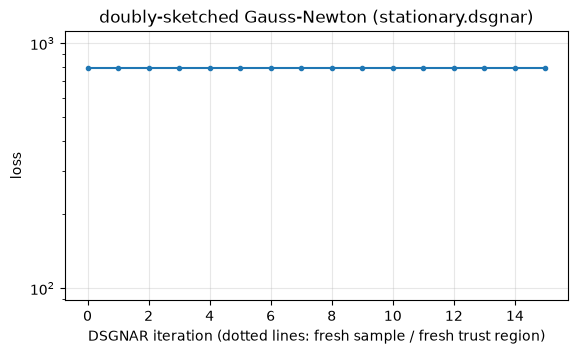

In [6]:
losses = [h["loss"] for h in history]

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.semilogy(range(len(losses)), losses, "o-", ms=3)
for c in range(1, DSGNAR_CYCLES):
    ax.axvline(c * DSGNAR_CYCLE_STEPS, color="grey", ls=":", lw=1)
ax.set(xlabel="DSGNAR iteration (dotted lines: fresh sample / fresh trust region)",
       ylabel="loss", title="doubly-sketched Gauss-Newton (stationary.dsgnar)")
ax.grid(alpha=0.3)
fig.savefig(FIGDIR / "dsgnar_loss.png", dpi=140, bbox_inches="tight")
print("saved", FIGDIR / "dsgnar_loss.png")
plt.show()


SSBroyden polish: 1000 iteration(s) in 36.8s | loss 5.9249e+02 -> 8.7397e-02 | 1000 updates, 0 skipped
SSBroyden from x0: 1000 iteration(s) in 30.2s | loss 5.9249e+02 -> 8.7397e-02

best of the two: loss 8.7397e-02
saved /serafin/reula/Julia/PINN/ldc/figures/optimizers_loss.png


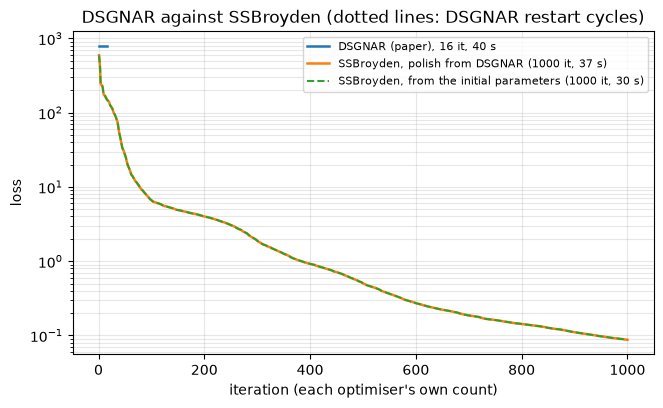

In [7]:
# ── SSBroyden, and the comparison with DSGNAR ────────────────────────────────────────
# The old SciPy-style `Crunch.Optimizers.minimize` failed from a far start (status 3 = zoom
# failed after a few iterations); the merged Crunch's line searches do not fail.  Per
# REPORT_OPTIMISERS.md, SSBroyden is the polisher: it starts from DSGNAR's result, on a fixed
# objective.  `QN_FROM_START` additionally runs it from the initial parameters, which is the
# far-start case the report says is DSGNAR's job -- the two curves show that.
from Crunch.Optimizers.minimize_backtracking import minimize as minimize_merged

fun_val = jax.jit(objective._loss)
fun_val_grad = jax.jit(jax.value_and_grad(objective._loss))


def run_ssbroyden(x_start, n_iter):
    """One Crunch call per iteration, carrying the inverse Hessian, recording each loss.

    The merged Crunch reports diagnostics, not a loss trajectory.  A one-iteration call with
    the carried ``hess_inv`` reproduces a single long call (checked: final losses agree to
    1e-5 relative) and gives exactly the per-iteration accepted loss the figure needs.
    """
    x, H, hist, upd, skip = jnp.asarray(x_start), None, [], 0, 0
    t0 = time.perf_counter()
    for k in range(n_iter):
        opts = {"maxiter": 1, "gtol": 1e-9, "update_method": "ssbroyden2",
                "line_search": "wolfe", "max_iter": 100, "scale_invariant": True,
                "alphamin": 1e-15, "initial_scale": (k == 0)}
        if H is not None:
            opts["initial_H"] = H
        r = minimize_merged(fun_val, fun_val_grad, x, opts)
        x, H = r.x, r.hess_inv
        st = r.stats or {}
        upd += int(st.get("n_update", 0) or 0)
        skip += int(st.get("n_skip", 0) or 0)
        hist.append((k + 1, float(r.fun)))
    return x, hist, time.perf_counter() - t0, dict(updates=upd, skipped=skip)


QN_FROM_START = True          # also run SSBroyden from the initial parameters (the far start)

flat_qn, qn_hist, qn_seconds, qn_stats = run_ssbroyden(flat, QN_MAXITER)
print(f"SSBroyden polish: {len(qn_hist)} iteration(s) in {qn_seconds:.1f}s | "
      f"loss {qn_hist[0][1]:.4e} -> {qn_hist[-1][1]:.4e} | "
      f"{qn_stats['updates']} updates, {qn_stats['skipped']} skipped")
if QN_FROM_START:
    _, qn0_hist, qn0_seconds, qn0_stats = run_ssbroyden(flat0, QN_MAXITER)
    print(f"SSBroyden from x0: {len(qn0_hist)} iteration(s) in {qn0_seconds:.1f}s | "
          f"loss {qn0_hist[0][1]:.4e} -> {qn0_hist[-1][1]:.4e}")

best = flat_qn if qn_hist[-1][1] <= objective.loss(flat) else flat
print(f"\nbest of the two: loss {objective.loss(best):.4e}")

# ── both optimisers in one figure ────────────────────────────────────────────────────
ds_loss = [h["loss"] for h in history]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.semilogy(range(1, len(ds_loss) + 1), ds_loss, "-", lw=1.8,
            label=f"DSGNAR ({'paper' if PAPER else 'safeguarded'}), "
                  f"{len(ds_loss)} it, {dsgnar_seconds:.0f} s")
for c in range(1, DSGNAR_CYCLES):
    ax.axvline(sum(cycle_lengths[:c]), color="grey", ls=":", lw=1)
ax.semilogy([k for k, _ in qn_hist], [v for _, v in qn_hist], "-", lw=1.8,
            label=f"SSBroyden, polish from DSGNAR ({len(qn_hist)} it, {qn_seconds:.0f} s)")
if QN_FROM_START:
    ax.semilogy([k for k, _ in qn0_hist], [v for _, v in qn0_hist], "--", lw=1.4,
                label=f"SSBroyden, from the initial parameters "
                      f"({len(qn0_hist)} it, {qn0_seconds:.0f} s)")
ax.set(xlabel="iteration (each optimiser's own count)", ylabel="loss",
       title="DSGNAR against SSBroyden (dotted lines: DSGNAR restart cycles)")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8)
fig.savefig(FIGDIR / "optimizers_loss.png", dpi=140, bbox_inches="tight")
print("saved", FIGDIR / "optimizers_loss.png")
plt.show()


## Results

The pressure field is defined only up to a constant, so it is compared after removing the mean.
The reference is the numerical solution in `ldc/reference_gen/ldc_reference.npz`.
### The reference field

`ldc/reference_gen/ldc_reference.npz` is the vorticity/streamfunction solution on a 129x129 grid at
Re = 100, converged to a relative vorticity residual of 4e-11; `div u` is at machine precision in the
interior and the boundary conditions are exact.  Validation of the generator
(`ldc/reference_gen/make_ldc_reference.py`):

* uniform-lid run against Ghia et al. (1982), Re = 100: `max|du| = 4.3e-3`, `max|dv| = 8.4e-3`;
* grid convergence: `max|du|` between 65x65 and 129x129 is 1.1e-2, between 129x129 and 193x193 it is
  1.4e-3 (second order), so the 129x129 field is converged well below any PINN error;
* primary vortex at (0.617, 0.750) against Ghia's (0.617, 0.734).


reference: ldc_reference.npz | 16641 points | channels ['u', 'v', 'p']
  rel L2  u: 2.211e-02
  rel L2  v: 3.535e-02
  rel L2  p: 5.587e-02
saved /serafin/reula/Julia/PINN/ldc/figures/fields_u.png


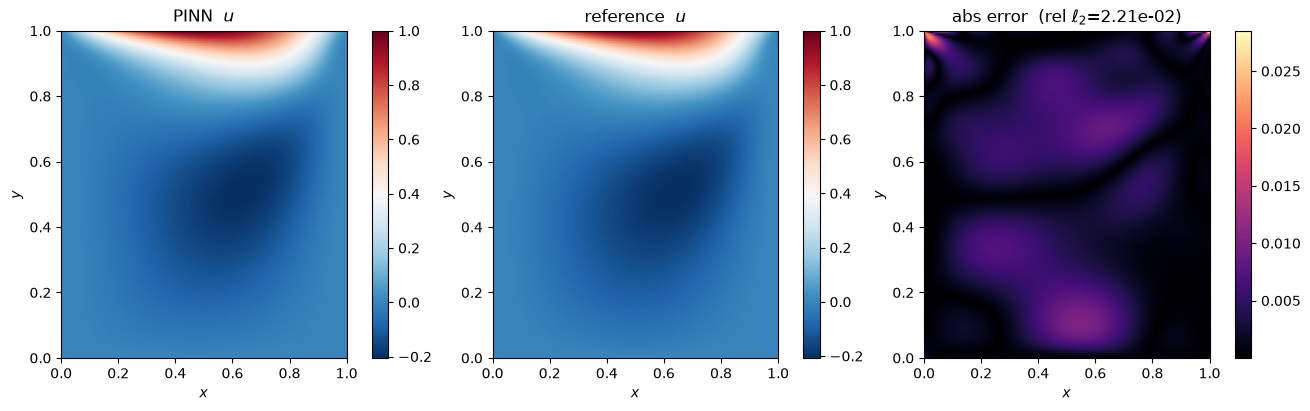

saved /serafin/reula/Julia/PINN/ldc/figures/fields_v.png


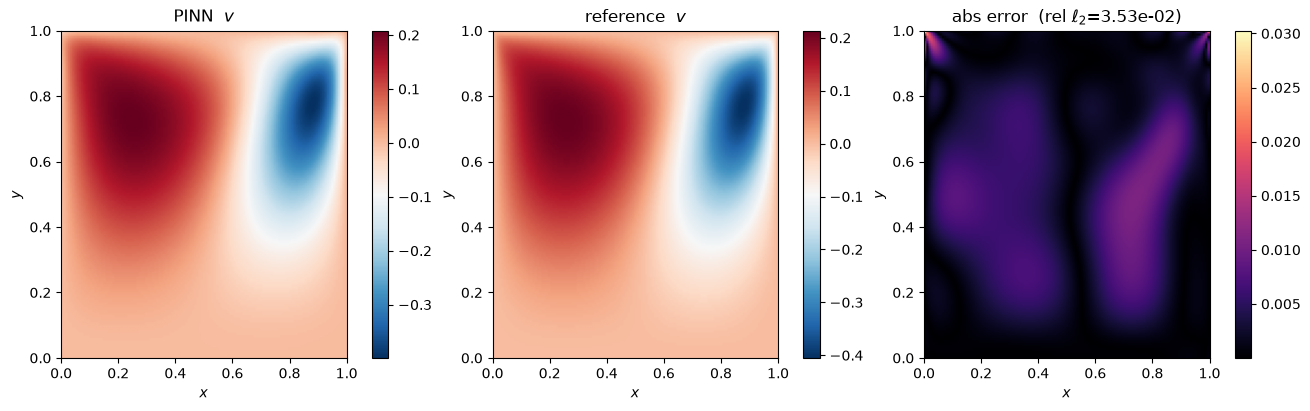

saved /serafin/reula/Julia/PINN/ldc/figures/fields_p.png


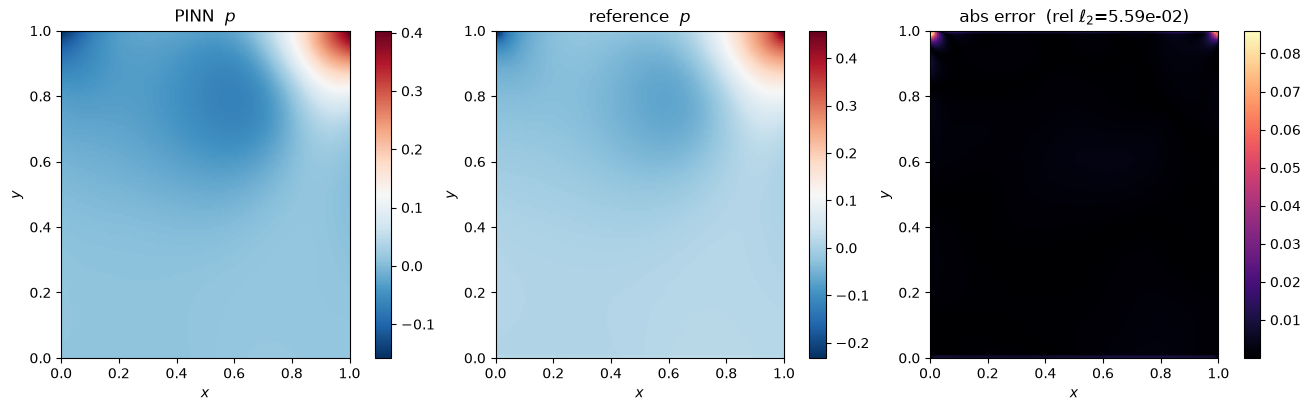

In [8]:
ref_path = REPO / "ldc" / "reference_gen" / "ldc_reference.npz"
if not ref_path.exists():
    raise FileNotFoundError(f"{ref_path} is missing -- run "
                            f"ldc/reference_gen/make_ldc_reference.py first")
ref = np.load(ref_path)
channels = [str(c) for c in ref["channels"]]
coords, exact = ref["coords"], ref["solution"]


def predict(params, pts):
    """Model output at arbitrary points, shape (n, out_dim)."""
    return np.asarray(jax.jit(jax.vmap(lambda c: forward(params, c)))(jnp.asarray(pts)))


params_best = unflatten(best)   # the optimisers carry flat vectors; the model wants the pytree

print(f"reference: {ref_path.name} | {coords.shape[0]} points | channels {channels}")
pred = predict(params_best, coords)
for i, ch in enumerate(channels):
    p, e = pred[:, i], exact[:, i]
    if ch == "p":
        p, e = p - p.mean(), e - e.mean()
    print(f"  rel L2  {ch}: {np.linalg.norm(p - e) / np.linalg.norm(e):.3e}")

x0, x1 = ref["plot_x0"], ref["plot_x1"]
extent = [x0[0], x0[-1], x1[0], x1[-1]]
grid_pts = np.stack(np.meshgrid(x0, x1, indexing="ij"), axis=-1).reshape(-1, 2)
pred_grid = predict(params_best, grid_pts).reshape(x0.size, x1.size, -1)

for i, ch in enumerate(channels):
    p = pred_grid[..., i]
    e = np.array(ref[f"plot_{ch}"])
    if ch == "p":
        p, e = p - p.mean(), e - e.mean()
    err = np.abs(p - e)
    rel = np.linalg.norm(p - e) / np.linalg.norm(e)

    fig, axs = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
    for ax, data, title, cmap in zip(
        axs, [p, e, err],
        [f"PINN  ${ch}$", f"reference  ${ch}$",
         f"abs error  (rel $\\ell_2$={rel:.2e})"],
        ["RdBu_r", "RdBu_r", "magma"],
    ):
        im = ax.imshow(data.T, origin="lower", aspect="auto", extent=extent, cmap=cmap)
        ax.set(xlabel="$x$", ylabel="$y$", title=title)
        fig.colorbar(im, ax=ax)
    fig.savefig(FIGDIR / f"fields_{ch}.png", dpi=140, bbox_inches="tight")
    print("saved", FIGDIR / f"fields_{ch}.png")
    plt.show()